In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sacc

import baccoemu
mpk = baccoemu.Matter_powerspectrum(nonlinear_model_name='Arico2023')

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


In [ ]:
fname = '/home/mzennaro/CosmoCodes/Notebooks/TestClLike/data/cls_cov_GSSC_20260313.fits'
s = sacc.Sacc.load_fits(fname)

In [3]:
from cobaya.model import get_model

In [4]:
kmax = 4.0
paramfile = 'compare_cl_like_files/test_DES_minimise_lmax4500.yml'
model = get_model(paramfile)

[model] *WARNING* Ignored blocks/options: ['sampler', 'force', 'output']
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.


In [ ]:
pars = {}
# with open('../chains/test_DES_kmax4.0.minimum', 'r') as f:
with open('compare_cl_like_files/test_DES_GSSC_lmax4500.minimum', 'r') as f:
    lines = f.readlines()
    for i in range(len(lines)):
        if (i > 2) & (i < 25):
            w = lines[i].split()
            pars[w[2]] = float(w[1])


print('-----------------------------------')
for key in pars:
    print('%20s \t %g'%(key, pars[key]))
print('-----------------------------------')

-----------------------------------
               A_sE9 	 2.12174
             Omega_m 	 0.309909
                   h 	 0.686672
             Omega_b 	 0.0616739
                 n_s 	 1.04305
                 M_c 	 13.5166
                 eta 	 -0.2993
                beta 	 -0.199556
           M1_z0_cen 	 11.6905
           theta_inn 	 -0.833179
           theta_out 	 0.227195
               M_inn 	 11.8591
   bias_DESY3wl__0_m 	 -0.0062983
   bias_DESY3wl__1_m 	 -0.01969
   bias_DESY3wl__2_m 	 -0.0265481
   bias_DESY3wl__3_m 	 -0.0354792
limber_DESY3wl__0_dz 	 0.00487793
limber_DESY3wl__1_dz 	 -0.00361057
limber_DESY3wl__2_dz 	 -0.00472961
limber_DESY3wl__3_dz 	 0.00365068
   bias_DESY3wl_A_IA 	 0.139753
limber_DESY3wl_eta_IA 	 0.00534004
-----------------------------------


In [ ]:
pars['n_s'] = 0.974135
pars['Omega_b'] = 0.05

In [7]:
logp = model.logposterior(pars)
print(logp)

No bias model, only pk_ww
[jax._src.xla_bridge] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


E1022 16:39:46.412554   42289 xtile_compiler.cc:399] Fusion: gemm_fusion_dot_general.1 = f32[4,30,49]{2,1,0} fusion(bitcast.3, bitcast.2), kind=kCustom, calls=gemm_fusion_dot_general.1_computation.clone, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"4","output_tiles":[{"sizes":["1","64","64"]}],"num_ctas":1,"num_stages":4,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E1022 16:39:46.412601   42289 xtile_compiler.cc:401] Computation: gemm_fusion_dot_general.1_computation.clone {
  parameter_0 = f32[30,4,100]{2,1,0} parameter(0)
  parameter_1 = f32[4,100,49]{2,1,0} parameter(1)
  ROOT dot = f32[4,30,49]{2,1,0} dot(parameter_0, parameter_1), lhs_batch_dims={1}, lhs_contracting_dims={2}, rhs_batch_dims={0}, rhs_contracting_dims={1}, backend_config={"sizes":

LogPosterior(logpost=np.float64(-180.15319783552965), logpriors=[np.float64(23.590864096940614)], loglikes=array([-203.74406193]), derived=[np.float64(0.8231713809392172), np.float64(0.8366556743242695)], finite=False)


In [9]:
ll = model.likelihood['cl_like.ClLike']

cls_th = ll.provider.get_cl_theory()

In [42]:
import pickle
with open('compare_cl_like_files/cls_th_cl_like_DES_wl.pkl', 'rb') as f:
    saved_cls_th = pickle.load(f)
if not np.allclose(cls_th, saved_cls_th):
    print('cls_th and saved_cls_th are not equal')
else:
    print('cls_th and saved_cls_th are equal')

cls_th and saved_cls_th are equal


In [10]:
allbins = ll.twopoints

print(allbins)
print(len(allbins))

[{'bins': ['DESY3wl__0', 'DESY3wl__0']}, {'bins': ['DESY3wl__0', 'DESY3wl__1']}, {'bins': ['DESY3wl__0', 'DESY3wl__2']}, {'bins': ['DESY3wl__0', 'DESY3wl__3']}, {'bins': ['DESY3wl__1', 'DESY3wl__1']}, {'bins': ['DESY3wl__1', 'DESY3wl__2']}, {'bins': ['DESY3wl__1', 'DESY3wl__3']}, {'bins': ['DESY3wl__2', 'DESY3wl__2']}, {'bins': ['DESY3wl__2', 'DESY3wl__3']}, {'bins': ['DESY3wl__3', 'DESY3wl__3']}]
10


In [11]:
name_conversion = {
    'DESY3wl__0' : 'wl 0',
    'DESY3wl__1' : 'wl 1',
    'DESY3wl__2' : 'wl 2',
    'DESY3wl__3' : 'wl 3'
}

In [12]:
from scipy.stats import chi2 as chi2dist
from scipy.stats import norm as normdist


N_datapoints = len(ll.data_vec)
N_params = len(pars)
N_dof = N_datapoints - 7 # N_params
chi2 = -2*logp.loglike

print('chi2', chi2)
print('N_datapoints', N_datapoints)
print('N_params', N_params)
print('N_dof', N_dof)
print('chi2_Ndatapoints', chi2dist.ppf(0.95, N_datapoints))
print('chi2_Ndof', chi2dist.ppf(0.95, N_dof))
print('p-value', 1-chi2dist.cdf(chi2, N_dof))
p_value = 1-chi2dist.cdf(chi2, N_dof)
z_score = normdist.ppf(1-p_value/2)
print('z-score', z_score)

chi2 407.4881238649405
N_datapoints 350
N_params 22
N_dof 343
chi2_Ndatapoints 394.62576022092185
chi2_Ndof 387.18806687530895
p-value 0.009439080532354427
z-score 2.5957278162472077


In [13]:
from cl_like_free import Likelihood

In [14]:
fits_file = '/home/mzennaro/CosmoCodes/Notebooks/TestClLike/data/cls_cov_GSSC_20260313.fits'
bins = [
    {'name': 'DESY3wl__0'},
    {'name': 'DESY3wl__1'},
    {'name': 'DESY3wl__2'},
    {'name': 'DESY3wl__3'},
]
twopoints = [
    {'bins': ['DESY3wl__0', 'DESY3wl__0']},
    {'bins': ['DESY3wl__0', 'DESY3wl__1']},
    {'bins': ['DESY3wl__0', 'DESY3wl__2']},
    {'bins': ['DESY3wl__0', 'DESY3wl__3']},
    {'bins': ['DESY3wl__1', 'DESY3wl__1']},
    {'bins': ['DESY3wl__1', 'DESY3wl__2']},
    {'bins': ['DESY3wl__1', 'DESY3wl__3']},
    {'bins': ['DESY3wl__2', 'DESY3wl__2']},
    {'bins': ['DESY3wl__2', 'DESY3wl__3']},
    {'bins': ['DESY3wl__3', 'DESY3wl__3']},
]
defaults = {
    'DESY3wl__0': {'lmin': 20, 'lmax': 8500},
    'DESY3wl__1': {'lmin': 20, 'lmax': 8500},
    'DESY3wl__2': {'lmin': 20, 'lmax': 8500},
    'DESY3wl__3': {'lmin': 20, 'lmax': 8500},
}
ia_parameters = {
    'ia_model': 'IADESY1_PerSurvey',
    'input_params_prefix': 'ia'

    # 'ia_model': 'IANone'
}
magnification_bias_parameters = {
    'use_magnification_bias': True,
    'input_params_prefix': 'mag'
}
nz_uncertainty_parameters = {
    'nz_model': 'NzShift',
    'input_params_prefix': 'nz'
}
shape_model_parameters = {
    'shape_model': 'ShapeMultiplicative',
    'input_params_prefix': 'shape'
}

print('Number of cross-correlations: ', len(twopoints))
print('')

myll = Likelihood(fits_file=fits_file, bins=bins, twopoints=twopoints, defaults=defaults, sample_type='convolve', bias_input_name='bias', use_baryons=True, ia_parameters=ia_parameters, magnification_bias_parameters=magnification_bias_parameters, nz_uncertainty_parameters=nz_uncertainty_parameters, shape_model_parameters=shape_model_parameters, debug=True)

Number of cross-correlations:  10

Loading l-bias lpt emulator...
L-bias lpt emulator loaded in memory.
Loading smeared bao emulator...
Smeared bao emulator loaded in memory.
Loading non-linear l-bias emulator...
Nonlinear l-bias emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded i

In [15]:
sampling_params = {
    # 'Omega_cdm': 0.309909-0.0616739-0.06/93.14/0.686672**2,
    'Omega_cdm': 0.309909-0.05-0.06/93.14/0.686672**2,
    # 'Omega_b': 0.0616739,
    'Omega_b': 0.05,
    'h': 0.686672,
    # 'n_s': 1.04305,
    'n_s': 0.974135,
    'A_s': 2.12174e-9,
    'w0': -1.0,
    'wa': 0.0,
    'M_nu': 0.06,

    'ia_DESY3wl_A_IA': 0.139753,
    'ia_DESY3wl_eta_IA': 0.00534004,

    # 'ia_DESY3wl_A_IA': -1.0,
    'ia_DESY3wl_eta_IA': 0.0,

    'nz_DESY3wl__0_dz': 0.00487793,
    'nz_DESY3wl__1_dz': -0.00361057,
    'nz_DESY3wl__2_dz': -0.00472961,
    'nz_DESY3wl__3_dz': 0.00365068,

    'shape_DESY3wl__0_m': -0.0062983,
    'shape_DESY3wl__1_m': -0.01969,
    'shape_DESY3wl__2_m': -0.0265481,
    'shape_DESY3wl__3_m': -0.0354792,

    'M_c': 13.5166,
    'eta': -0.2993,
    'beta': -0.199556,
    'M1_z0_cen': 11.6905,
    'theta_inn': -0.833179,
    'theta_out': 0.227195,
    'M_inn': 11.8591
}

print('Number of sampling parameters: ', len(sampling_params))

# theory_vector = myll.get_theory_vector(sampling_params)
theory_vector = myll.get_theory_perbin(sampling_params)
this_chi2 = myll.get_chi2(sampling_params)

Number of sampling parameters:  25
WARNIG: in debug mode, NOT clearing cache for heft_calculator and mpk_calculator
WARNIG: in debug mode, NOT clearing cache for heft_calculator and mpk_calculator


/home/mzennaro/miniconda3/envs/cosmobacco2/lib/python3.11/site-packages/sacc/sacc.py:436: UserWarning: Empty index selected - maybe you should check the tracer order?
  warnings.warn("Empty index selected - maybe you "


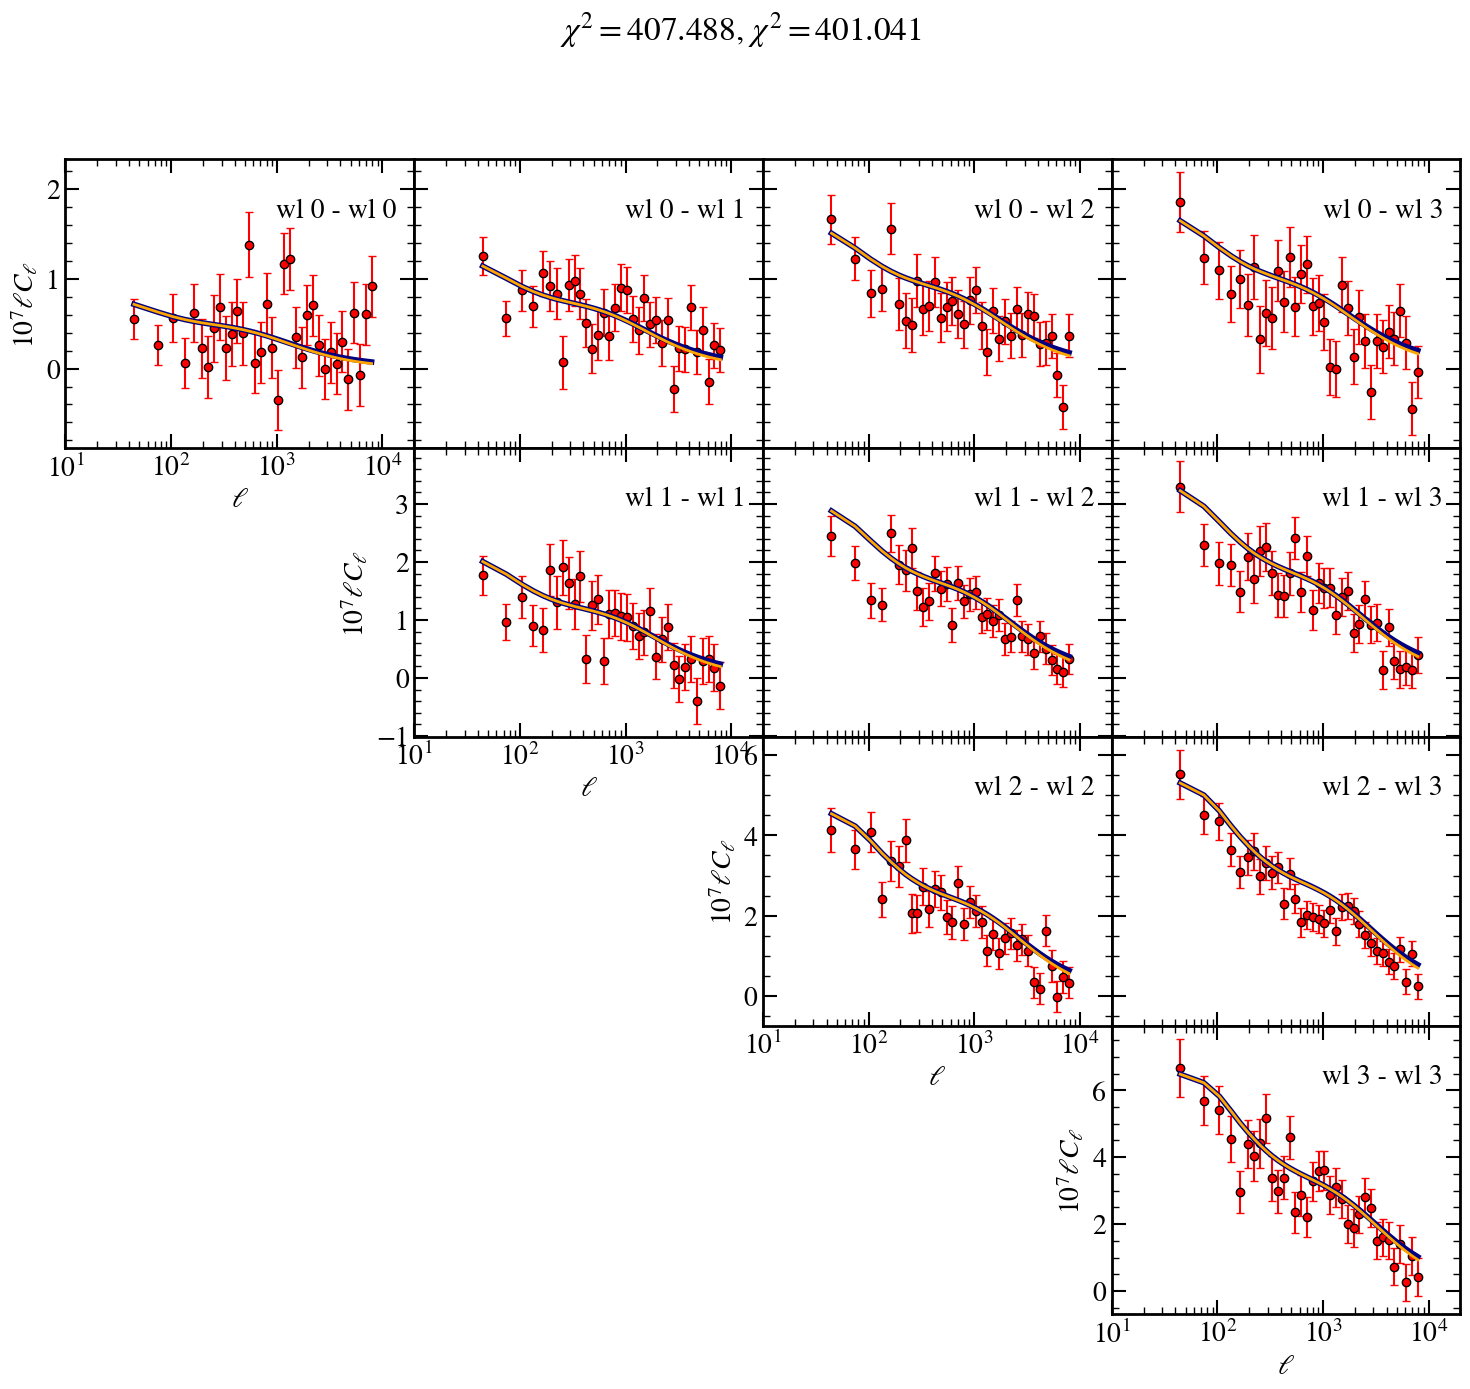

In [16]:
fig, ax = plt.subplots(4, 4, figsize=(18, 15), sharex=True, sharey='row', gridspec_kw={'wspace':0 , 'hspace': 0})
ax = ax.flatten()

ii = 0
for i in range(4):
    for j in range(4):
        i_ax = i*4 + j
        if j >= i:
            bins = allbins[ii]
            t1, t2 = bins['bins']

            ell_eff, cl, cov_cl = s.get_ell_cl('cl_00', t1, t2, return_cov=True)
            norm = 10*ell_eff*(ell_eff+1)
            # mask if you don't want to see it all until ell eight trillion and a half
            ell_mask = ell_eff < 10000
            norm = norm[ell_mask]
            ax[i_ax].errorbar(ell_eff[ell_mask], norm * cl[ell_mask], norm * np.sqrt(np.diag(cov_cl))[ell_mask], fmt='o', capsize=3, ms=6, color='0.9')

            inds = ll.cl_meta[ii]['inds']

            # data and model with scale cuts
            datacol = 'r'
            # modelcol = 'purple'
            modelcol = 'navy'
            mymodelcol = 'orange'
            ell = ll.cl_meta[ii]['l_eff']
            norm = ell*1e7
            ax[i_ax].errorbar(ell, norm * ll.data_vec[inds], norm * np.sqrt(np.diag(ll.cov)[inds]), fmt='o', capsize=3, ms=6, color=datacol, mec='k')
            ax[i_ax].semilogx(ell, norm * cls_th[inds], color=modelcol, lw=4, zorder=10)
            ax[i_ax].semilogx(ell, norm * theory_vector[f'{t1}_{t2}'], color=mymodelcol, lw=2, zorder=10)
            ax[i_ax].text(0.95, 0.8, '%s - %s' % (name_conversion[t1], name_conversion[t2]), transform=ax[i_ax].transAxes, fontsize=20, ha='right')
            ii += 1
        else:
            ax[i_ax].set_axis_off()


for i in range(4):
    for j in range(4):
        if j >= i:
            if i*4+j in [0, 5, 10, 15]:
                ax[i*4 + j].tick_params(axis='y', which='both', left=True, labelleft=True)
                ax[i*4 + j].set_ylabel(r'$10^{7} \ell C_\ell$')
                ax[i*4 + j].tick_params(axis='x', which='both', bottom=True, labelbottom=True)
                ax[i*4 + j].set_xlabel(r'$\ell$')
                ax[i*4 + j].set_xlim(10, 20000)

fig.suptitle(r'$\chi^2=%g$, $\chi^2=%g$'%(-2*logp.loglike, this_chi2))

plt.show()

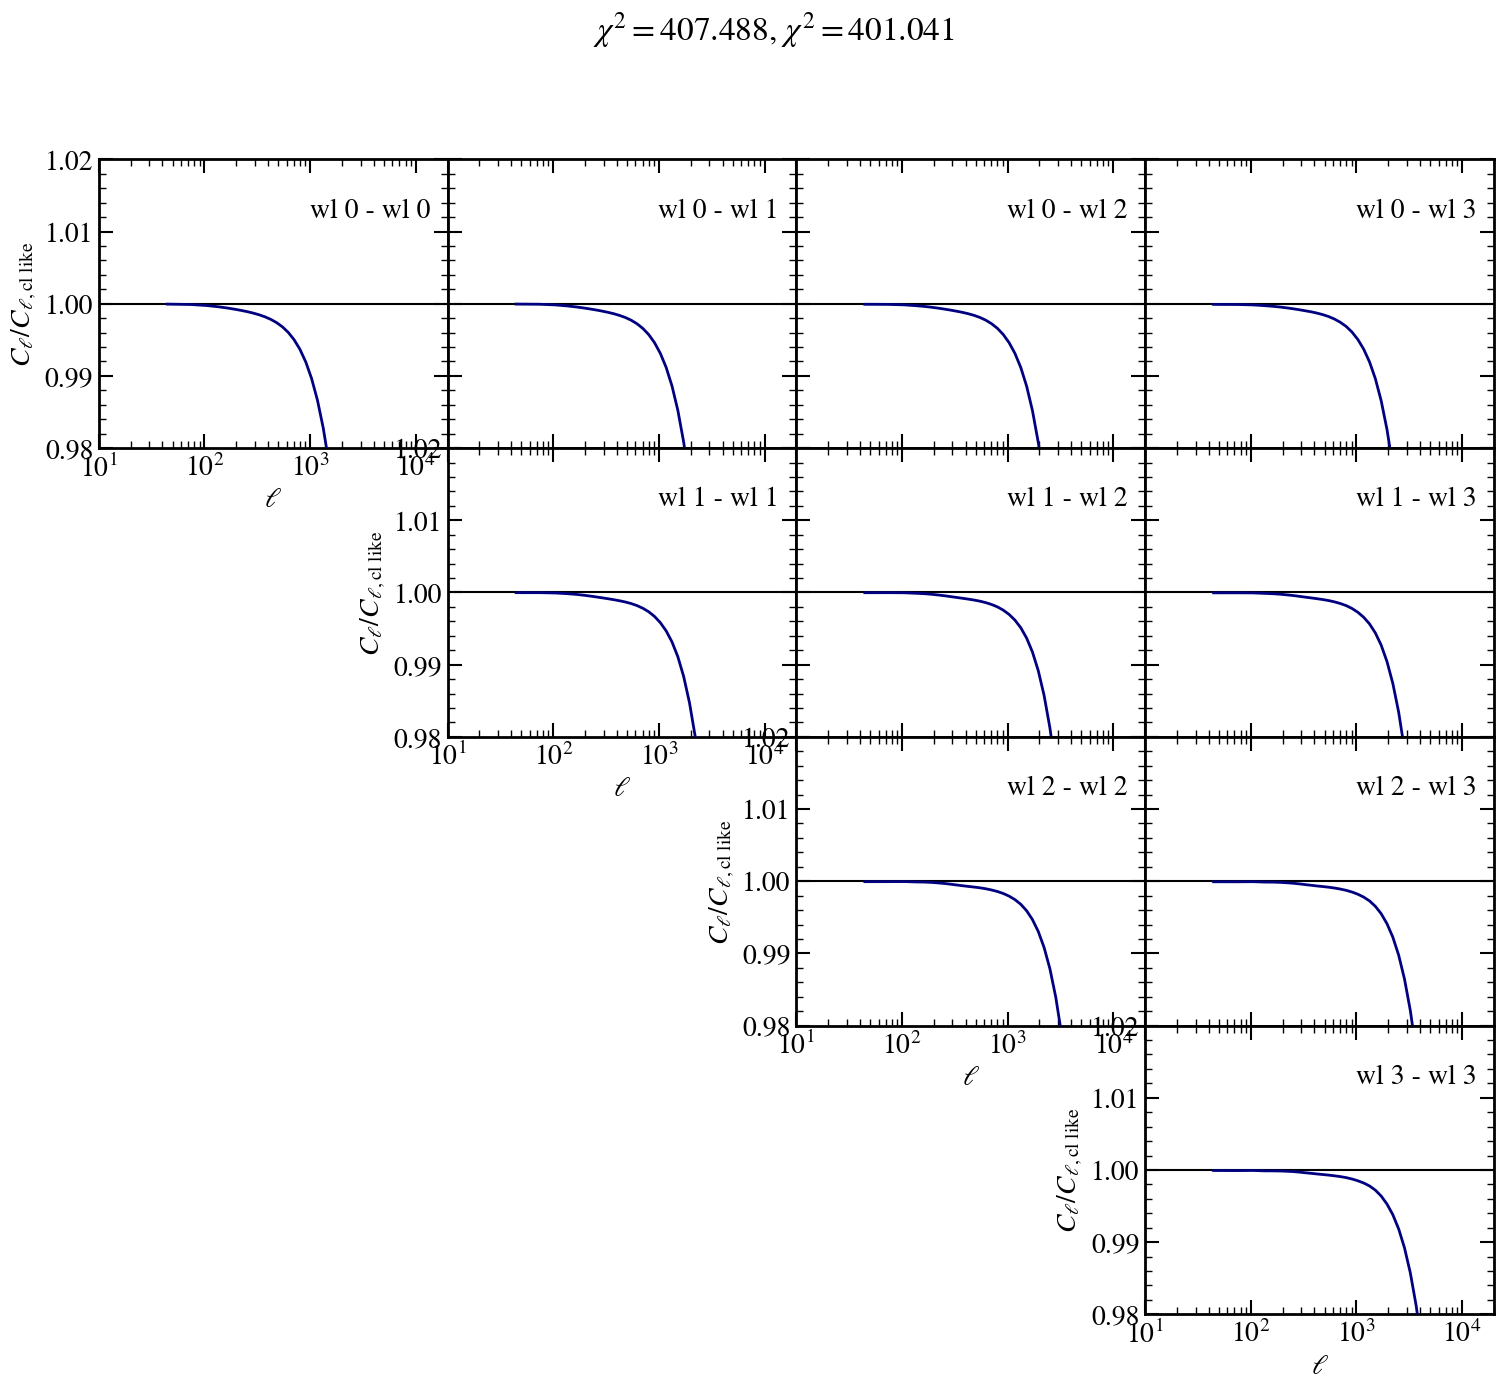

In [17]:
fig, ax = plt.subplots(4, 4, figsize=(18, 15), sharex=True, sharey='row', gridspec_kw={'wspace':0 , 'hspace': 0})
ax = ax.flatten()

ii = 0
for i in range(4):
    for j in range(4):
        i_ax = i*4 + j
        if j >= i:
            bins = allbins[ii]
            t1, t2 = bins['bins']

            ell_eff, cl, cov_cl = s.get_ell_cl('cl_00', t1, t2, return_cov=True)
            norm = 10*ell_eff*(ell_eff+1)
            # mask if you don't want to see it all until ell eight trillion and a half
            ell_mask = ell_eff < 2000
            norm = norm[ell_mask]

            inds = ll.cl_meta[ii]['inds']

            ax[i_ax].axhline(1, color='k')
            ax[i_ax].semilogx(ell, theory_vector[f'{t1}_{t2}'] / cls_th[inds], color=modelcol, lw=2, zorder=10)
            ax[i_ax].text(0.95, 0.8, '%s - %s' % (name_conversion[t1], name_conversion[t2]), transform=ax[i_ax].transAxes, fontsize=20, ha='right')
            ax[i_ax].set_ylim(0.98, 1.02)
            ii += 1
        else:
            ax[i_ax].set_axis_off()


for i in range(4):
    for j in range(4):
        if j >= i:
            if i*4+j in [0, 5, 10, 15]:
                ax[i*4 + j].tick_params(axis='y', which='both', left=True, labelleft=True)
                ax[i*4 + j].set_ylabel(r'$C_\ell / C_{\ell, \mathrm{cl \,\,like}}$')
                ax[i*4 + j].tick_params(axis='x', which='both', bottom=True, labelbottom=True)
                ax[i*4 + j].set_xlabel(r'$\ell$')
                ax[i*4 + j].set_xlim(10, 20000)

fig.suptitle(r'$\chi^2=%g$, $\chi^2=%g$'%(-2*logp.loglike, this_chi2))

plt.show()

In [18]:
ll.cl_meta[0]

{'bin_1': 'DESY3wl__0',
 'bin_2': 'DESY3wl__0',
 'l_eff': array([  44.5,   74.5,  104.5,  134.5,  164.5,  194.5,  224.5,  255.5,
         290. ,  329.5,  374. ,  424.5,  482. ,  547. ,  621. ,  705. ,
         800.5,  909. , 1032. , 1172. , 1331. , 1511.5, 1716.5, 1949. ,
        2213. , 2513. , 2853.5, 3240. , 3679.5, 4178.5, 4745. , 5388.5,
        6119. , 6948.5, 7890.5]),
 'cl': array([ 1.23169157e-09,  3.52236379e-10,  5.40197931e-10,  4.72736598e-11,
         3.77179285e-10,  1.14601030e-10,  7.82923475e-12,  1.74811130e-10,
         2.37066037e-10,  6.91570459e-11,  1.01856326e-10,  1.50035522e-10,
         8.11250385e-11,  2.51504752e-10,  1.03637731e-11,  2.52981358e-11,
         8.97343343e-11,  2.56977053e-11, -3.34941021e-11,  9.96425954e-11,
         9.13111899e-11,  2.30208822e-11,  7.23503898e-12,  3.05220833e-11,
         3.16940680e-11,  1.01947695e-11, -9.52934838e-14,  5.51585098e-12,
         1.49257580e-12,  7.15719255e-12, -2.54590495e-12,  1.15305607e-11,
       

In [19]:
print(myll.cl_meta[0]['l_eff'].shape)
print(myll.cl_meta[0]['l_bpw'].shape)
print(myll.cl_meta[0]['w_bpw'].shape)
print(myll.cl_meta[0]['pixbeam'].shape)

print(model.likelihood['cl_like.ClLike'].cl_meta[0]['l_eff'].shape)
print(model.likelihood['cl_like.ClLike'].cl_meta[0]['l_bpw'].shape)
print(model.likelihood['cl_like.ClLike'].cl_meta[0]['w_bpw'].shape)
print(model.likelihood['cl_like.ClLike'].cl_meta[0]['pixbeam'].shape)

(35,)
(12288,)
(35, 12288)
(100,)
(35,)
(12288,)
(35, 12288)
(100,)


In [20]:
myll.theory.l_sample

array([0.0000e+00, 2.0000e+00, 3.0000e+00, 4.0000e+00, 5.0000e+00,
       6.0000e+00, 7.0000e+00, 8.0000e+00, 9.0000e+00, 1.0000e+01,
       1.1000e+01, 1.2000e+01, 1.4000e+01, 1.5000e+01, 1.6000e+01,
       1.7000e+01, 1.9000e+01, 2.0000e+01, 2.2000e+01, 2.4000e+01,
       2.6000e+01, 2.8000e+01, 3.0000e+01, 3.3000e+01, 3.5000e+01,
       3.8000e+01, 4.1000e+01, 4.5000e+01, 4.8000e+01, 5.2000e+01,
       5.6000e+01, 6.1000e+01, 6.6000e+01, 7.1000e+01, 7.7000e+01,
       8.4000e+01, 9.0000e+01, 9.8000e+01, 1.0600e+02, 1.1400e+02,
       1.2400e+02, 1.3400e+02, 1.4500e+02, 1.5600e+02, 1.6900e+02,
       1.8300e+02, 1.9800e+02, 2.1400e+02, 2.3100e+02, 2.5000e+02,
       2.7000e+02, 2.9200e+02, 3.1500e+02, 3.4100e+02, 3.6900e+02,
       3.9900e+02, 4.3100e+02, 4.6600e+02, 5.0400e+02, 5.4500e+02,
       5.8900e+02, 6.3600e+02, 6.8800e+02, 7.4400e+02, 8.0400e+02,
       8.6900e+02, 9.4000e+02, 1.0160e+03, 1.0980e+03, 1.1870e+03,
       1.2830e+03, 1.3870e+03, 1.5000e+03, 1.6210e+03, 1.7530e

In [21]:
model.theory['cl_like.Limber'].l_sample

array([0.0000e+00, 2.0000e+00, 3.0000e+00, 4.0000e+00, 5.0000e+00,
       6.0000e+00, 7.0000e+00, 8.0000e+00, 9.0000e+00, 1.0000e+01,
       1.1000e+01, 1.2000e+01, 1.4000e+01, 1.5000e+01, 1.6000e+01,
       1.7000e+01, 1.9000e+01, 2.0000e+01, 2.2000e+01, 2.4000e+01,
       2.6000e+01, 2.8000e+01, 3.0000e+01, 3.3000e+01, 3.5000e+01,
       3.8000e+01, 4.1000e+01, 4.5000e+01, 4.8000e+01, 5.2000e+01,
       5.6000e+01, 6.1000e+01, 6.6000e+01, 7.1000e+01, 7.7000e+01,
       8.4000e+01, 9.0000e+01, 9.8000e+01, 1.0600e+02, 1.1400e+02,
       1.2400e+02, 1.3400e+02, 1.4500e+02, 1.5600e+02, 1.6900e+02,
       1.8300e+02, 1.9800e+02, 2.1400e+02, 2.3100e+02, 2.5000e+02,
       2.7000e+02, 2.9200e+02, 3.1500e+02, 3.4100e+02, 3.6900e+02,
       3.9900e+02, 4.3100e+02, 4.6600e+02, 5.0400e+02, 5.4500e+02,
       5.8900e+02, 6.3600e+02, 6.8800e+02, 7.4400e+02, 8.0400e+02,
       8.6900e+02, 9.4000e+02, 1.0160e+03, 1.0980e+03, 1.1870e+03,
       1.2830e+03, 1.3870e+03, 1.5000e+03, 1.6210e+03, 1.7530e

In [22]:
print(myll.theory.sample_cen)
print(myll.theory.sample_bpw)

print(model.theory['cl_like.Limber'].sample_cen)
print(model.theory['cl_like.Limber'].sample_bpw)

False
True
False
True


In [23]:
print(model.theory['cl_like.Pk'].a_s_pks.shape)
print(model.theory['cl_like.Pk'].a_s_pks)
print(model.theory['cl_like.Pk'].bacco_calc.a_s.shape)
print(model.theory['cl_like.Pk'].bacco_calc.a_s)

(30,)
[0.4        0.4084507  0.41726619 0.42647059 0.43609023 0.44615385
 0.45669291 0.46774194 0.47933884 0.49152542 0.50434783 0.51785714
 0.53211009 0.54716981 0.5631068  0.58       0.59793814 0.61702128
 0.63736264 0.65909091 0.68235294 0.70731707 0.73417722 0.76315789
 0.79452055 0.82857143 0.86567164 0.90625    0.95081967 1.        ]
(30,)
[0.4        0.4084507  0.41726619 0.42647059 0.43609023 0.44615385
 0.45669291 0.46774194 0.47933884 0.49152542 0.50434783 0.51785714
 0.53211009 0.54716981 0.5631068  0.58       0.59793814 0.61702128
 0.63736264 0.65909091 0.68235294 0.70731707 0.73417722 0.76315789
 0.79452055 0.82857143 0.86567164 0.90625    0.95081967 1.        ]


In [24]:
print(model.theory['cl_like.Pk'].bacco_calc.ks.shape)
print(model.theory['cl_like.Pk'].bacco_calc.ks)
print(model.theory['cl_like.Pk'].bacco_calc.ks_sh_sh.shape)
print(model.theory['cl_like.Pk'].bacco_calc.ks_sh_sh)

(35,)
[0.008      0.00903462 0.01020305 0.01152259 0.01301278 0.01469569
 0.01659625 0.01874261 0.02116655 0.02390397 0.02699541 0.03048667
 0.03442944 0.03888213 0.04391066 0.04958953 0.05600283 0.06324555
 0.07142496 0.08066219 0.09109405 0.10287504 0.11617963 0.13120488
 0.14817332 0.16733624 0.18897746 0.21341749 0.24101829 0.27218864
 0.30739019 0.34714427 0.39203966 0.44274127 0.5       ]
(113,)
[1.00000000e-04 1.12430375e-04 1.26405893e-04 1.42118620e-04
 1.59784498e-04 1.79646311e-04 2.01977022e-04 2.27083524e-04
 2.55310859e-04 2.87046957e-04 3.22727971e-04 3.62844269e-04
 4.07947174e-04 4.58656539e-04 5.15669269e-04 5.79768895e-04
 6.51836345e-04 7.32862050e-04 8.23959553e-04 9.26380819e-04
 1.04153343e-03 1.17099995e-03 1.31655964e-03 1.48021294e-03
 1.66420897e-03 1.87107639e-03 2.10365821e-03 2.36515082e-03
 2.65914795e-03 2.98969002e-03 3.36131971e-03 3.77914437e-03
 4.24890620e-03 4.77706120e-03 5.37086784e-03 6.03848687e-03
 6.78909346e-03 7.63300326e-03 8.58181422e-03 

In [25]:
pk2d = model.theory['cl_like.Pk'].bacco_calc.pk2d_computed
pk2d = pk2d['mm_sh_sh']

In [26]:
import pyccl as ccl


p3d = myll.theory.mpk_calculator.precomputed_pk
k = p3d['k']
p3d_mm = p3d['pk']
a_s = p3d['a_s']

if np.all(p3d_mm > 0):
    mypk2d = ccl.Pk2D(a_arr=a_s, lk_arr=np.log(k), pk_arr=np.log(p3d_mm), is_logp=True)
else:
    mypk2d = ccl.Pk2D(a_arr=a_s, lk_arr=np.log(k), pk_arr=p3d_mm, is_logp=False)

In [27]:
print(pk2d(0.1, 0.9))
print(mypk2d(0.1, 0.9))
print(pk2d.extrap_order_hik)
print(pk2d.extrap_order_lok)
print(mypk2d.extrap_order_hik)
print(mypk2d.extrap_order_lok)

9791.001790895793
9792.472153583993
2
1
2
1


In [28]:
print(model.theory['cl_like.Pk'].allow_bcm_emu_extrapolation_for_shear)
print(model.theory['cl_like.Pk'].allow_halofit_extrapolation_for_shear)
print(model.theory['cl_like.Pk'].allow_halofit_extrapolation_for_shear_on_k)

True
True
False


In [29]:
import baccoemu
mpk = baccoemu.Matter_powerspectrum(nonlinear_model_name='Arico2023')
# mpk = baccoemu.Matter_powerspectrum(nonlinear_model_name='Angulo2021')
baccoemu_cosmopars = myll.theory.sampler_to_bacco_params(sampling_params)
print(baccoemu_cosmopars)

Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Arico et al. (2021)...
Baryonic Emulator Arico et al. (2025) loaded in memory.
{'omega_cold': 0.3085427935253371, 'omega_baryon': 0.05, 'hubble': 0.686672, 'ns': 0.974135, 'neutrino_mass': 0.06, 'w0': -1.0, 'wa': 0.0, 'A_s': 2.12174e-09}


In [30]:
from scipy.interpolate import CubicSpline

def k_extrapolator(kk_out, k, pk):
    if len(pk.shape) == 1:
        pk = pk[None, :]
    log_k = np.log(k)
    log_k_extrap = np.log(kk_out)

    pk_extrap = []
    for i in range(len(pk)):
        if np.any(pk[i] <= 0):
            raise RuntimeError('Input power spectrum contains non-positive values')
        log_pk = np.log(pk[i])

        # cubicspline interpolation in log-log space
        spline = CubicSpline(log_k, log_pk, extrapolate=False)
        # linear extrapolation in log-log space
        log_pk_low = log_pk[0] + (log_pk[1] - log_pk[0]) / (log_k[1] - log_k[0]) * (log_k_extrap - log_k[0])
        log_pk_high = log_pk[-1] + (log_pk[-1] - log_pk[-2]) / (log_k[-1] - log_k[-2]) * (log_k_extrap - log_k[-1])
        log_pk_extrap = np.where(log_k_extrap < log_k[0], log_pk_low, np.where(log_k_extrap > log_k[-1], log_pk_high, spline(log_k_extrap)))
        pk_extrap.append(np.exp(log_pk_extrap))
    pk_extrap = np.array(pk_extrap)
    if pk_extrap.shape[0] == 1:
        pk_extrap = pk_extrap[0]
    return pk_extrap

In [31]:
sk2d = model.theory['cl_like.Pk'].bacco_calc.pk2d_computed
sk2d = sk2d['Sk']

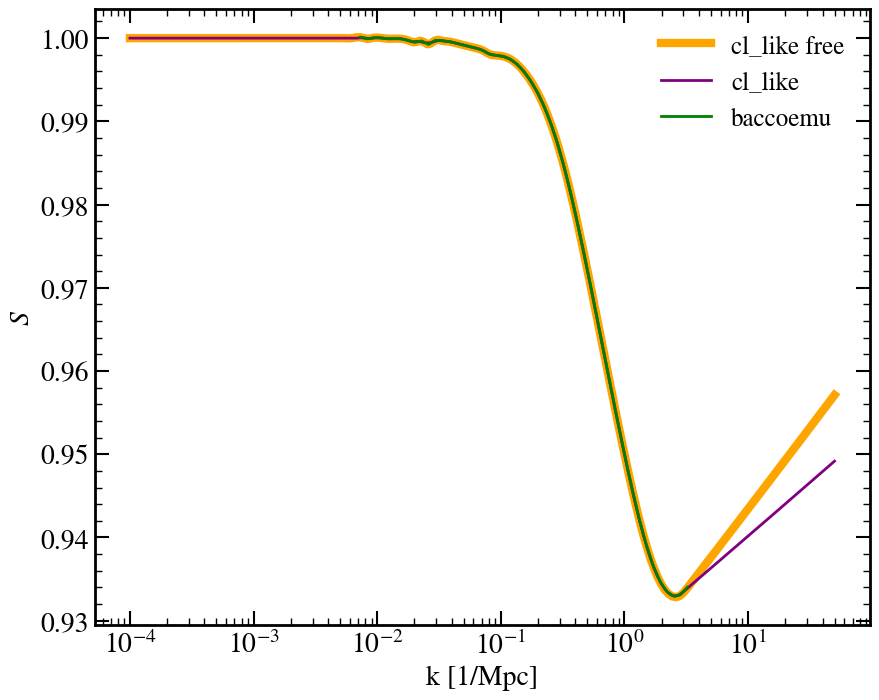

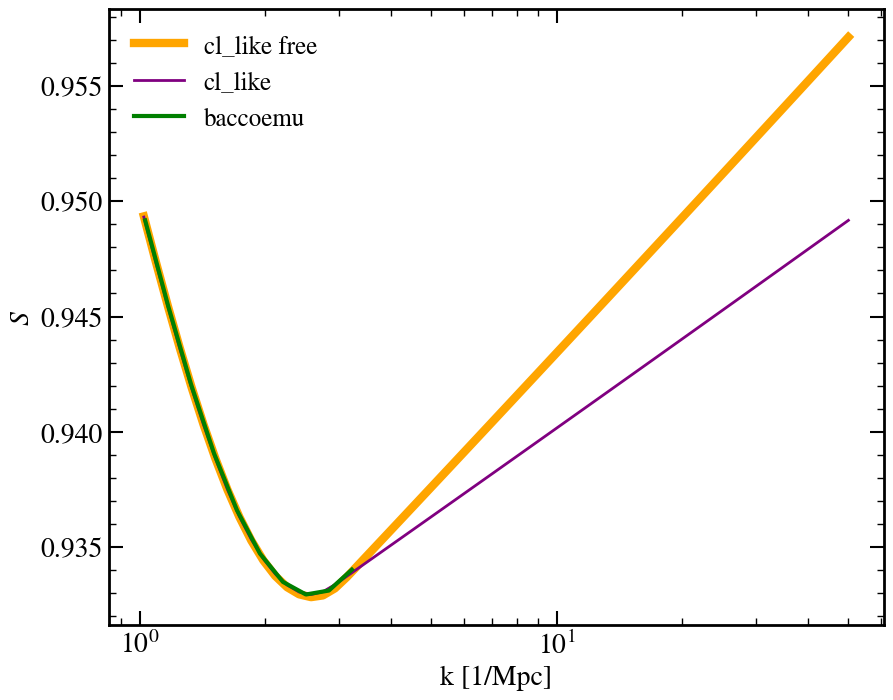

In [32]:
h = sampling_params['h']
bacco_cosmo = myll.theory.sampler_to_bacco_params(sampling_params)
baryon_params = {
    'M_c': sampling_params['M_c'],
    'eta': sampling_params['eta'],
    'beta': sampling_params['beta'],
    'M1_z0_cen': sampling_params['M1_z0_cen'],
    'theta_inn': sampling_params['theta_inn'],
    'theta_out': sampling_params['theta_out'],
    'M_inn': sampling_params['M_inn']
}
mySk = myll.theory.mpk_calculator.get_baccoemu_Sk(bacco_cosmo, baryon_params)

# emuk, emuSk = mpk.get_baryonic_boost(expfactor=mySk['a_s'], **bacco_cosmo, **baryon_params)

# fig, ax = plt.subplots(1, 1, figsize=(8, 6))
# ax.semilogx(emuk, (emuSk / mySk['Sk']).T, color='blue', lw=2)
# ax.set_xlabel(r'k [h/Mpc]')
# ax.set_ylabel(r'$S / S_{\text{cl like free}}$')
# ax.legend()
# plt.show()


_kk = np.logspace(-4, np.log10(50), 200)

emuk, emuSk = mpk.get_baryonic_boost(expfactor=0.9, **bacco_cosmo, **baryon_params)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.semilogx(_kk, mySk['Sk2d'](_kk, 0.9), color='orange', lw=6, label='cl_like free')
ax.semilogx(_kk, sk2d(_kk, 0.9), color='purple', lw=2, label='cl_like')
ax.semilogx(emuk*h, emuSk, color='green', lw=2, label='baccoemu')
ax.set_xlabel(r'k [1/Mpc]')
ax.set_ylabel(r'$S$')
ax.legend()
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
mask = (_kk > 1.0) & (_kk < 100)
emumask = (emuk*h > 1.0) & (emuk*h < 100)
ax.semilogx(_kk[mask], mySk['Sk2d'](_kk[mask], 0.9), color='orange', lw=6, label='cl_like free')
ax.semilogx(_kk[mask], sk2d(_kk[mask], 0.9), color='purple', lw=2, label='cl_like')
ax.semilogx(emuk[emumask]*h, emuSk[emumask], color='green', lw=3, label='baccoemu')
ax.set_xlabel(r'k [1/Mpc]')
ax.set_ylabel(r'$S$')
ax.legend()
plt.show()

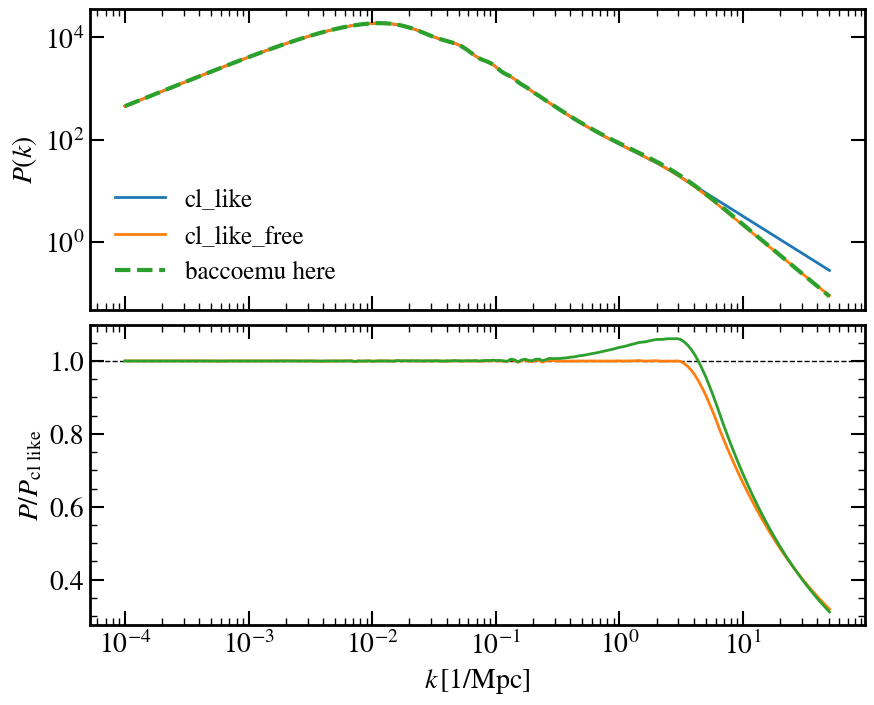

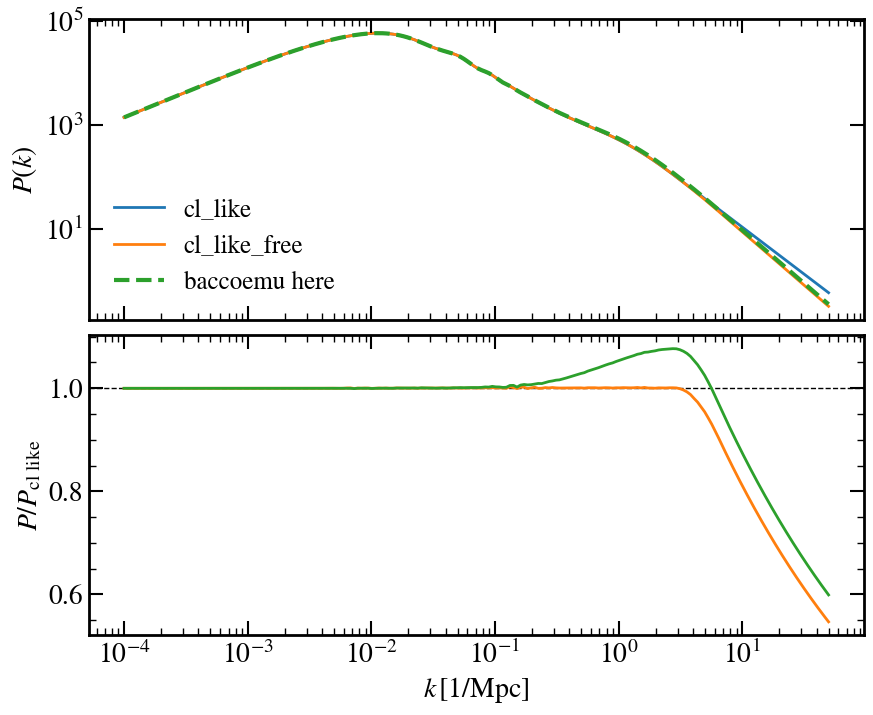

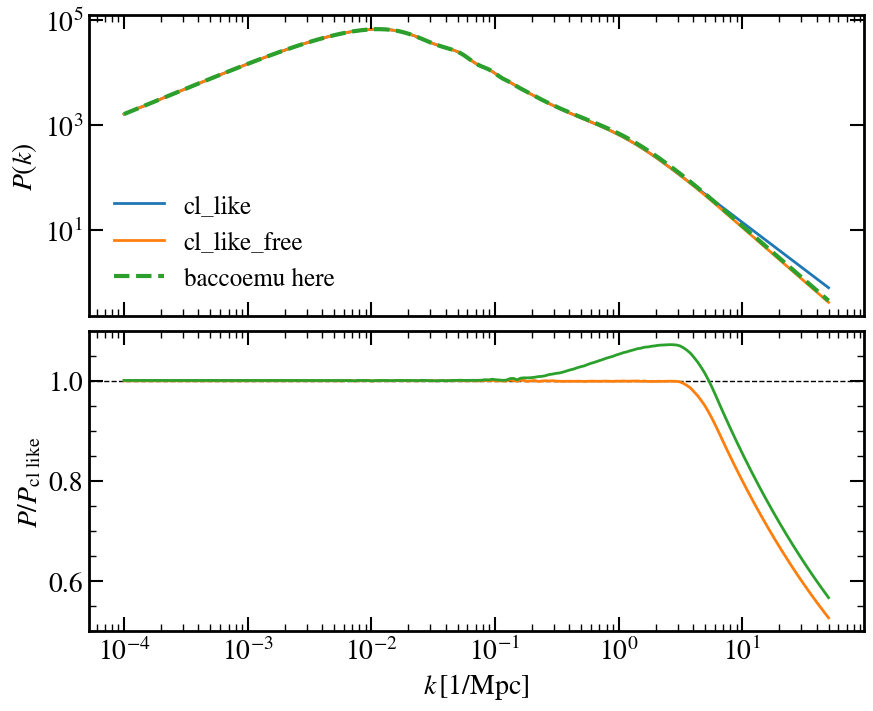

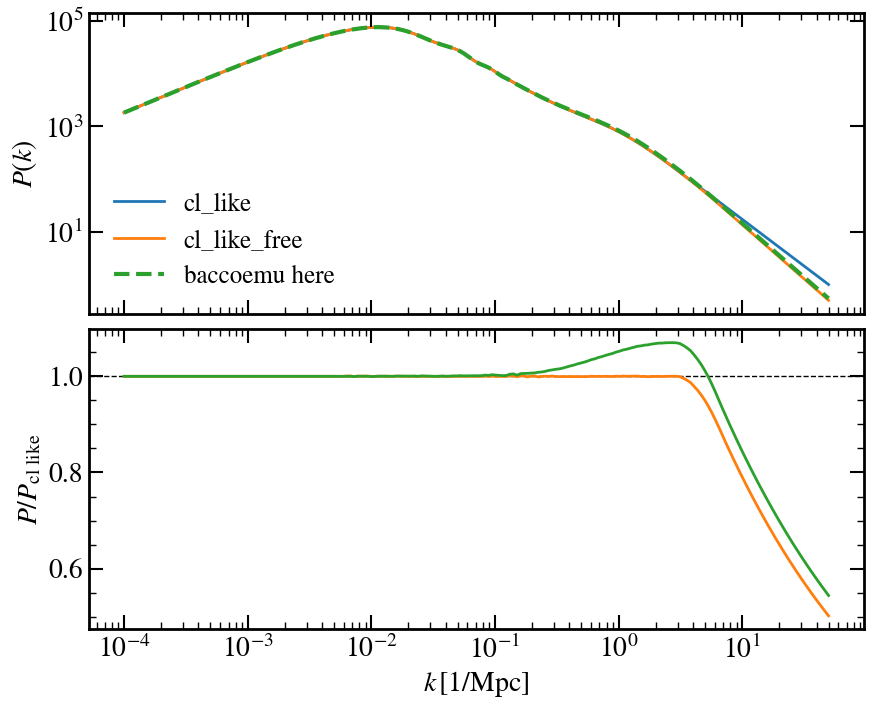

In [34]:
_kk = np.logspace(-4, np.log10(50), 200)
# _kk = mpk.emulator['nonlinear']['k'] * baccoemu_cosmopars['hubble']
h = baccoemu_cosmopars['hubble']
# pklin = mpk.get_linear_pk(k=_kk/h, expfactor=0.9, **baccoemu_cosmopars)[1]/h**3

# # let's track all the steps
new_a_s = np.linspace(0.4, 1.0, 30)
_kk_h = _kk / h
bacco_kmin, bacco_kmax = mpk.emulator['nonlinear']['k'].min(), mpk.emulator['nonlinear']['k'].max()
mask_for_bacco = (_kk_h <= bacco_kmax)
# here I was not adding back the high k extrapolation
# nl_pk = mpk.get_nonlinear_pk(cold=False, k=_kk_h[mask_for_bacco], expfactor=new_a_s, **baccoemu_cosmopars)[1]/h**3
# other_pk2d = ccl.Pk2D(a_arr=new_a_s, lk_arr=np.log(_kk[mask_for_bacco]), pk_arr=np.log(nl_pk), is_logp=True)
# here it is if I do it
nl_pk = mpk.get_nonlinear_pk(cold=False, k=_kk_h[mask_for_bacco], expfactor=new_a_s, **baccoemu_cosmopars)[1]/h**3
nl_pk = k_extrapolator(_kk, _kk[mask_for_bacco], nl_pk)
other_pk2d = ccl.Pk2D(a_arr=new_a_s, lk_arr=np.log(_kk), pk_arr=np.log(nl_pk), is_logp=True)

for aa in [0.4, 0.8, 0.9, 1.0]:

    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 8), gridspec_kw={'hspace': 0.05})

    # ax[0].loglog(_kk, pklin, label='linear', lw=3, ls='--', color='0.5')
    ax[0].loglog(_kk, pk2d(_kk, aa), label='cl_like', lw=2)
    ax[0].loglog(_kk, mypk2d(_kk, aa), label='cl_like_free', lw=2)
    ax[0].semilogx(_kk, other_pk2d(_kk, aa), label='baccoemu here', lw=3, ls='--')

    ax[0].set_ylabel(r'$P(k)$')
    ax[0].legend()

    ax[1].axhline(1, color='k', lw=1, ls='--')
    ax[1].semilogx(_kk, mypk2d(_kk, aa) / pk2d(_kk, aa), lw=2, color='C1')
    ax[1].semilogx(_kk, other_pk2d(_kk, aa) / pk2d(_kk, aa), lw=2, color='C2')

    ax[1].set_xlabel(r'$k \,[1/\mathrm{Mpc}]$')
    ax[1].set_ylabel(r'$P / P_{\text{cl like}}$')
    plt.show()

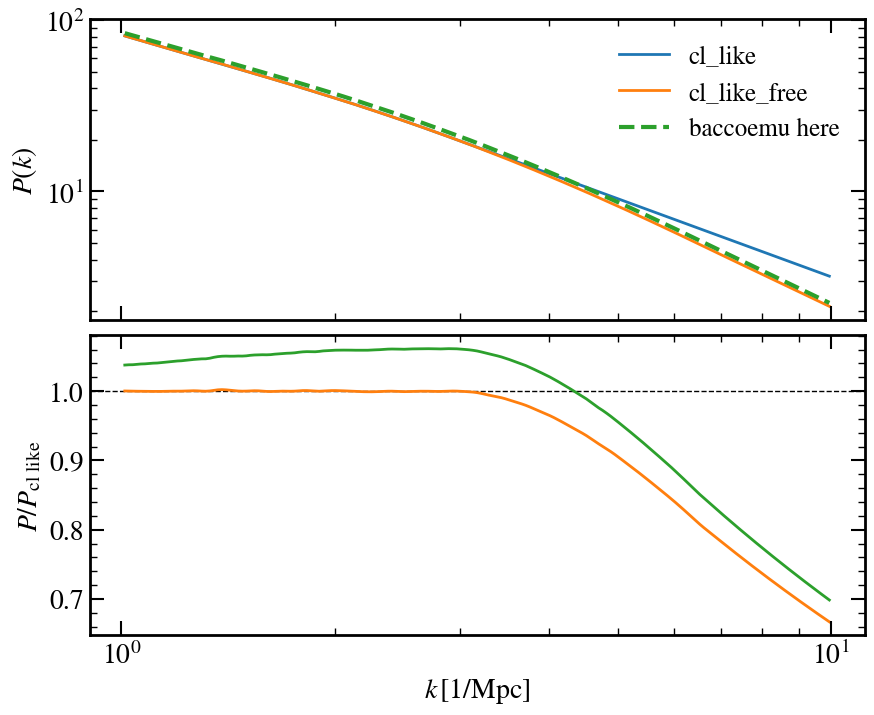

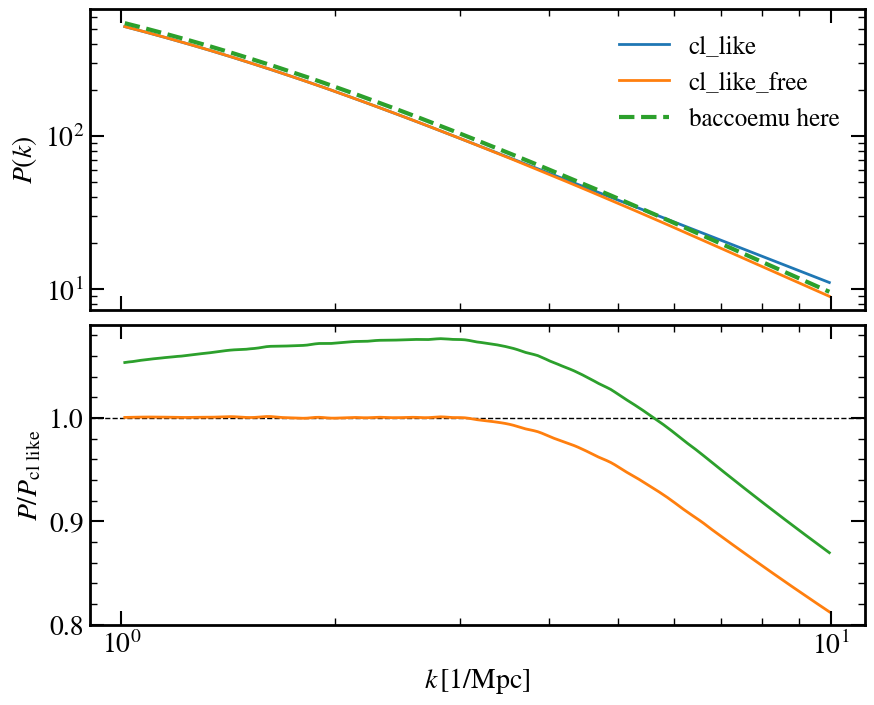

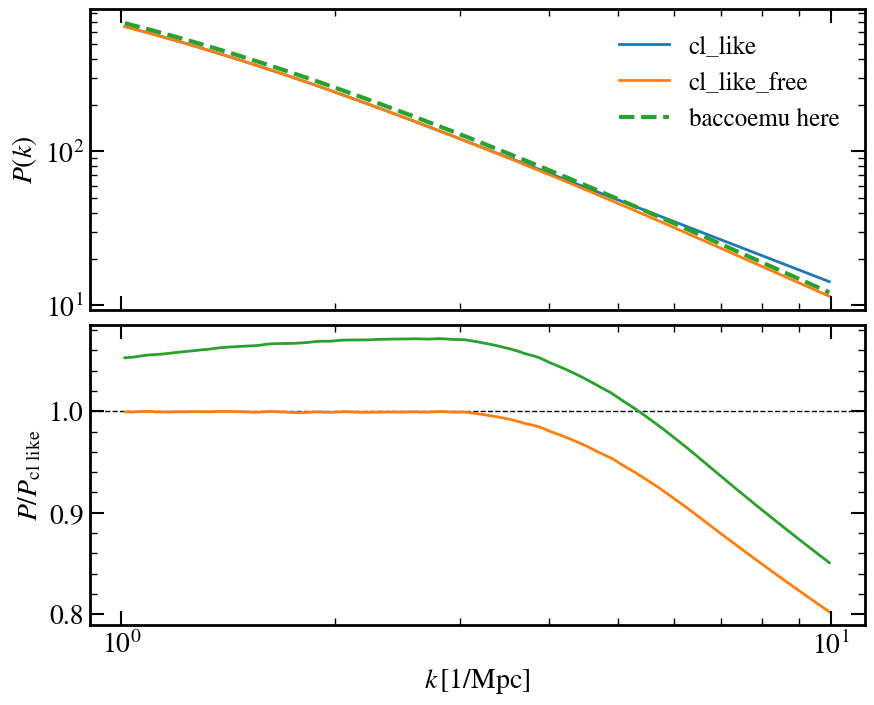

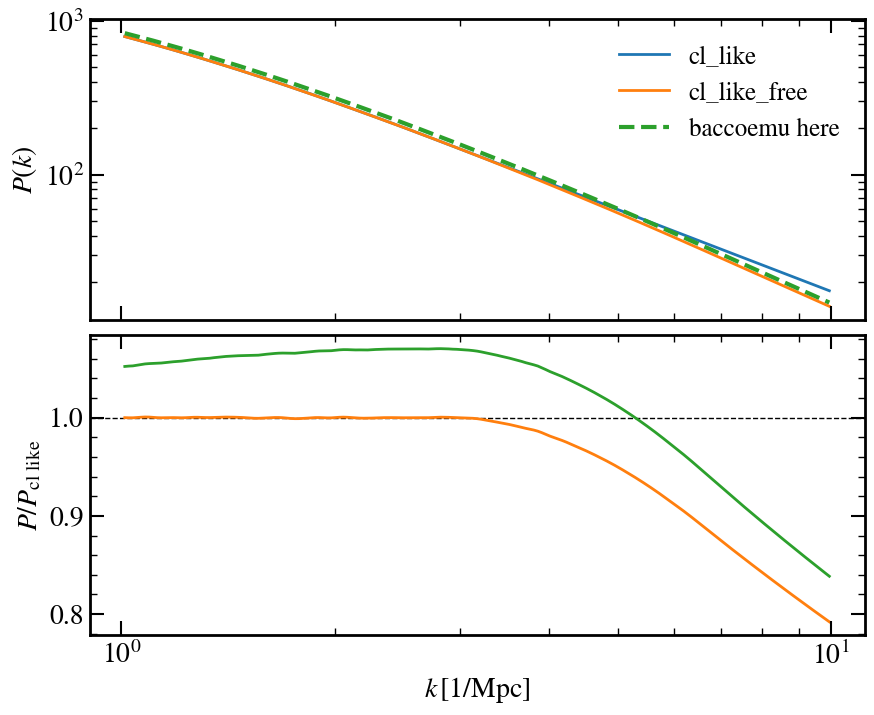

In [38]:
_kk = np.logspace(-4, np.log10(50), 1000)
# _kk = mpk.emulator['nonlinear']['k'] * baccoemu_cosmopars['hubble']
h = baccoemu_cosmopars['hubble']
# pklin = mpk.get_linear_pk(k=_kk/h, expfactor=0.9, **baccoemu_cosmopars)[1]/h**3

# # let's track all the steps
new_a_s = np.linspace(0.4, 1.0, 50)
_kk_h = _kk / h
bacco_kmin, bacco_kmax = mpk.emulator['nonlinear']['k'].min(), mpk.emulator['nonlinear']['k'].max()
mask_for_bacco = (_kk_h <= bacco_kmax)
# here I was not adding back the high k extrapolation
# nl_pk = mpk.get_nonlinear_pk(cold=False, k=_kk_h[mask_for_bacco], expfactor=new_a_s, **baccoemu_cosmopars)[1]/h**3
# other_pk2d = ccl.Pk2D(a_arr=new_a_s, lk_arr=np.log(_kk[mask_for_bacco]), pk_arr=np.log(nl_pk), is_logp=True)

# here it is if I do it
nl_pk = mpk.get_nonlinear_pk(cold=False, k=_kk_h[mask_for_bacco], expfactor=new_a_s, **baccoemu_cosmopars)[1]/h**3
nl_pk = k_extrapolator(_kk, _kk[mask_for_bacco], nl_pk)
other_pk2d = ccl.Pk2D(a_arr=new_a_s, lk_arr=np.log(_kk), pk_arr=np.log(nl_pk), is_logp=True)

for aa in [0.4, 0.8, 0.9, 1.0]:

    fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 8), gridspec_kw={'hspace': 0.05})

    zoom_mask = (_kk > 1.0) & (_kk < 10)

    # ax[0].loglog(_kk, pklin, label='linear', lw=3, ls='--', color='0.5')
    ax[0].loglog(_kk[zoom_mask], pk2d(_kk[zoom_mask], aa), label='cl_like', lw=2)
    ax[0].loglog(_kk[zoom_mask], mypk2d(_kk[zoom_mask], aa), label='cl_like_free', lw=2)
    ax[0].semilogx(_kk[zoom_mask], other_pk2d(_kk[zoom_mask], aa), label='baccoemu here', lw=3, ls='--')

    ax[0].set_ylabel(r'$P(k)$')
    ax[0].legend()

    ax[1].axhline(1, color='k', lw=1, ls='--')
    ax[1].semilogx(_kk[zoom_mask], mypk2d(_kk[zoom_mask], aa) / pk2d(_kk[zoom_mask], aa), lw=2, color='C1')
    ax[1].semilogx(_kk[zoom_mask], other_pk2d(_kk[zoom_mask], aa) / pk2d(_kk[zoom_mask], aa), lw=2, color='C2')

    ax[1].set_xlabel(r'$k \,[1/\mathrm{Mpc}]$')
    ax[1].set_ylabel(r'$P / P_{\text{cl like}}$')
    plt.show()